In [33]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [34]:
import os
train_folder = '/kaggle/input/datasets/ummaumaranasiba/dataset-food/food_data_english/train'
test_folder = '/kaggle/input/datasets/ummaumaranasiba/dataset-food/food_data_english/test'
print(os.listdir(train_folder))

['bakorkhani', 'beguni', 'biriyani', 'chickpeas', 'egg_omlete', 'fuchka', 'haleem', 'hilsha_fish', 'kabab', 'kacha_golla', 'kala_bhuna', 'khichuri', 'mashed_potato', 'morog_polao', 'nehari', 'porota', 'roshgolla', 'roshmalai', 'yogurt']


In [35]:
import torchvision.transforms as transforms
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),      
    transforms.ToTensor(),               
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])  
])

val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(), #0-1
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]) 
])

def denorm(img):   # undo Normalize for display: [-1,1] → [0,1]
    return (img * 0.5 + 0.5).clamp(0, 1)

train_data = datasets.ImageFolder(train_folder,transform = train_transform)
test_data = datasets.ImageFolder(test_folder,transform = val_transform)
print(f"Trn:{len(train_data)}")
print(f"Tst:{len(test_data)}")
print(f"Classes:{len(train_data.classes)}")
print(train_data.classes)

Trn:2973
Tst:1540
Classes:19
['bakorkhani', 'beguni', 'biriyani', 'chickpeas', 'egg_omlete', 'fuchka', 'haleem', 'hilsha_fish', 'kabab', 'kacha_golla', 'kala_bhuna', 'khichuri', 'mashed_potato', 'morog_polao', 'nehari', 'porota', 'roshgolla', 'roshmalai', 'yogurt']


Text(0.5, 1.0, 'fuchka')

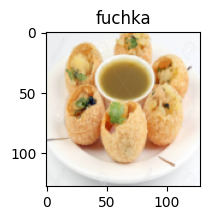

In [36]:
plt.figure(figsize = (2,2))
plt.imshow(denorm(train_data[800][0]).permute(1,2,0))
plt.title(train_data.classes[train_data[800][1]])

In [37]:
#important HyperParameters
batch_size = 32
learning_rate=0.001
minimum_learning_rate=1e-4
epochs = 25
num_classes = len(train_data.classes)   

In [38]:
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,num_workers=2, pin_memory=True)
val_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

In [39]:
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

class CNNModel(nn.Module):
    def __init__(self, num_classes=19):
        super(CNNModel, self).__init__()

        # Convolutional layers
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3,padding=1),  # 3x128x128 -> 32x128x128
            nn.MaxPool2d(2),                  # 32x64x64
            nn.ReLU(),

            nn.Conv2d(32,64 , kernel_size=3,padding=1),# 64x64x64
            nn.MaxPool2d(2),                  # 64x32x32
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3,padding=1),# 128x32x32
            nn.MaxPool2d(2),                   # 128x16x16
            nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=3,padding=1),# 256x16x16
            nn.MaxPool2d(2),                   # 256x8x8
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3,padding=1),# 256x8x8
            nn.MaxPool2d(2),                   # 256x4x4
            nn.ReLU()
        )

        # ANN
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256*4*4, 512),
            nn.ReLU(),
            nn.Linear(512,256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


model = CNNModel(num_classes=num_classes).to(device)

optimizer = Adam(model.parameters(), lr=learning_rate)

scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=minimum_learning_rate)

criterion = nn.CrossEntropyLoss()

from torchsummary import summary
summary(model, input_size=(3,128,128));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
         MaxPool2d-2           [-1, 32, 64, 64]               0
              ReLU-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 64, 64, 64]          18,496
         MaxPool2d-5           [-1, 64, 32, 32]               0
              ReLU-6           [-1, 64, 32, 32]               0
            Conv2d-7          [-1, 128, 32, 32]          73,856
         MaxPool2d-8          [-1, 128, 16, 16]               0
              ReLU-9          [-1, 128, 16, 16]               0
           Conv2d-10          [-1, 256, 16, 16]         295,168
        MaxPool2d-11            [-1, 256, 8, 8]               0
             ReLU-12            [-1, 256, 8, 8]               0
           Conv2d-13            [-1, 256, 8, 8]         590,080
        MaxPool2d-14            [-1, 25

In [40]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        total_loss += loss.item()

        
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(loader)
    train_acc = correct / total

    return train_loss, train_acc

def validate_epoch(model, loader, criterion, device):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_loss = total_loss / len(loader)
    val_acc = correct / total

    return val_loss, val_acc

In [41]:
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):
    print(f"----------------------------------------------------")
    print(f"Epoch {epoch+1}/{epochs}, LR: {optimizer.param_groups[0]['lr']:.6g}")

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

----------------------------------------------------
Epoch 1/25, LR: 0.001
Train Loss: 2.7643 | Train Acc: 0.1372
Val Loss: 3.2167 | Val Acc: 0.0331
----------------------------------------------------
Epoch 2/25, LR: 0.000996452
Train Loss: 2.6955 | Train Acc: 0.1547
Val Loss: 3.3127 | Val Acc: 0.0331
----------------------------------------------------
Epoch 3/25, LR: 0.000985862
Train Loss: 2.6453 | Train Acc: 0.1736
Val Loss: 3.2260 | Val Acc: 0.0403
----------------------------------------------------
Epoch 4/25, LR: 0.000968399
Train Loss: 2.5670 | Train Acc: 0.1897
Val Loss: 3.1638 | Val Acc: 0.0773
----------------------------------------------------
Epoch 5/25, LR: 0.000944338
Train Loss: 2.5177 | Train Acc: 0.2062
Val Loss: 3.1207 | Val Acc: 0.0649
----------------------------------------------------
Epoch 6/25, LR: 0.000914058
Train Loss: 2.4715 | Train Acc: 0.2173
Val Loss: 3.1616 | Val Acc: 0.0903
----------------------------------------------------
Epoch 7/25, LR: 0.00087

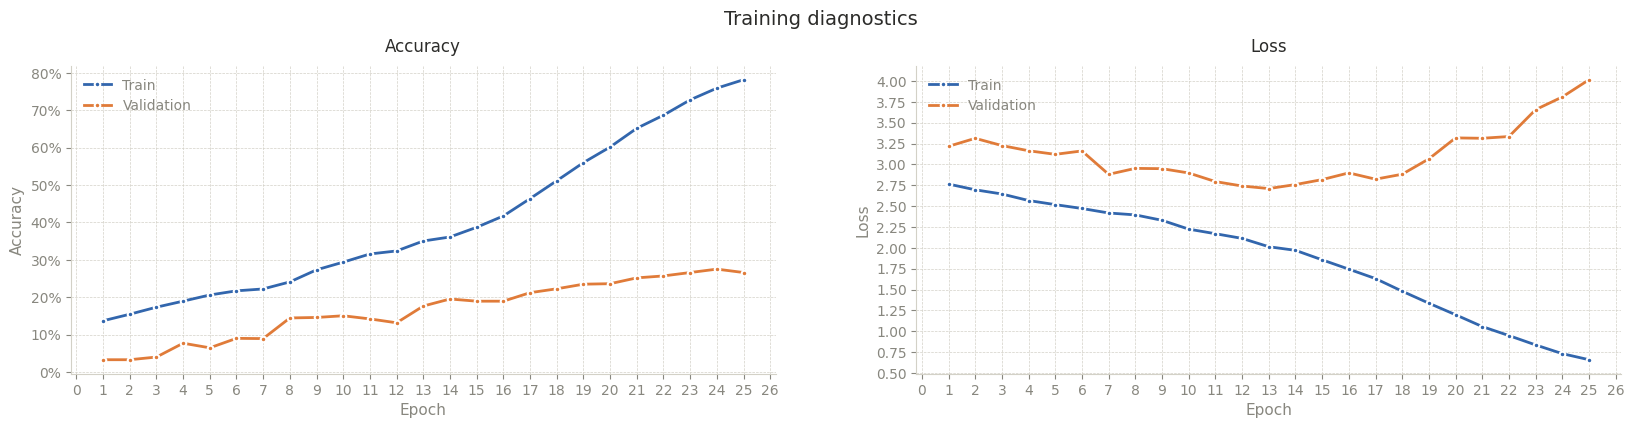

In [42]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import numpy as np

BLUE   = "#3266ad"
ORANGE = "#e07b39"
GRAY   = "#88877f"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#d3d1c7",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#d3d1c7",
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

epochs_number = np.arange(1, epochs + 1)
fig = plt.figure(figsize=(20, 4))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.2)

# ── Accuracy ──────────────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0])
ax1.plot(epochs_number, train_accuracies, color=BLUE,   lw=2,   label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax1.plot(epochs_number, val_accuracies,   color=ORANGE, lw=2,   label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-")
ax1.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))
ax1.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax1.set_ylabel("Accuracy", color=GRAY, fontsize=11)
ax1.set_title("Accuracy", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax1.legend(frameon=False, fontsize=10, labelcolor=GRAY)

# ── Loss ──────────────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1])
ax2.plot(epochs_number, train_losses, color=BLUE,   lw=2, label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax2.plot(epochs_number, val_losses,   color=ORANGE, lw=2, label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-")
ax2.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax2.yaxis.set_major_locator(mticker.MultipleLocator(0.25))   # loss range is wider with 19 classes
ax2.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax2.set_ylabel("Loss",  color=GRAY, fontsize=11)
ax2.set_title("Loss", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax2.legend(frameon=False, fontsize=10, labelcolor=GRAY)

fig.suptitle("Training diagnostics", fontsize=14, fontweight="medium", color="#2c2c2a", y=1.02)
plt.savefig("training_curves.pdf", bbox_inches="tight", dpi=150)
plt.show()

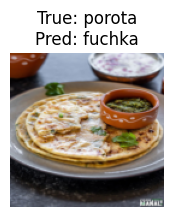

In [43]:
model.eval()
ix = torch.randint(0,len(test_data),())
img = test_data[ix][0].unsqueeze(0).to(device)
np_output = model(img).cpu().detach().numpy()
pred = np.exp(np_output)/np.sum(np.exp(np_output))
plt.figure(figsize=(2,2))
plt.imshow(denorm(img.squeeze(0).cpu()).permute(1,2,0).numpy())
plt.title(f"True: {test_data.classes[test_data[ix][1]]}\nPred: {test_data.classes[pred[0].argmax()]}")
plt.axis('off')
plt.show()

Total misclassified samples: 1130


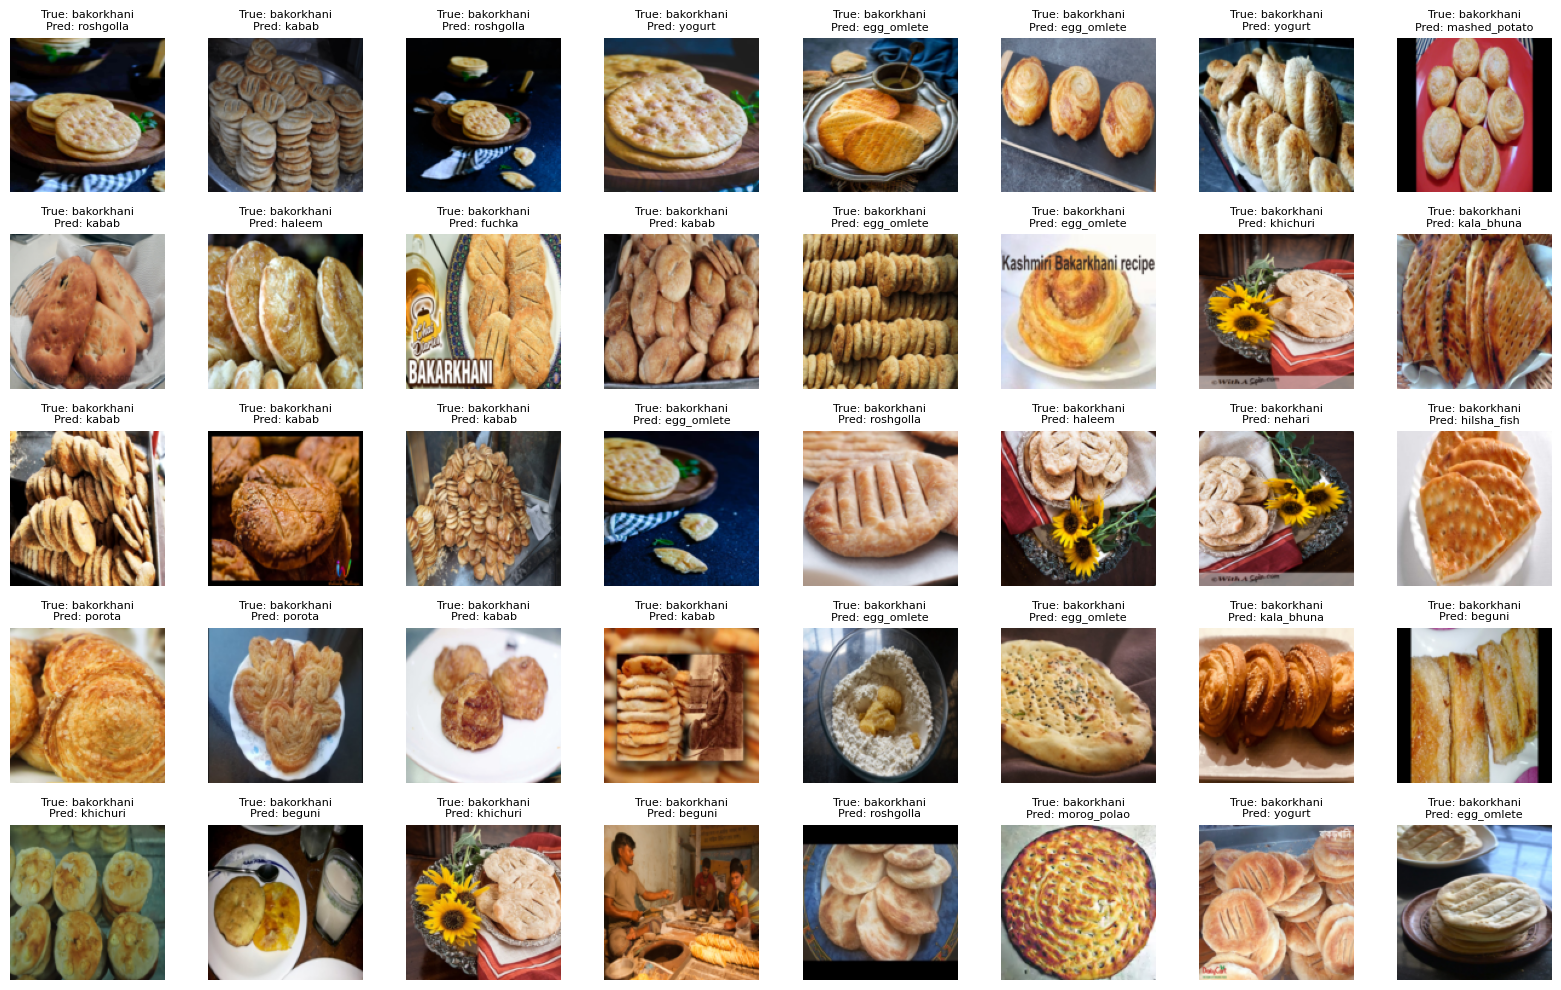

In [44]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

class_names = test_data.classes  # from ImageFolder

model.eval()
misclassified = []
all_preds = []
all_labels = []


with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

      
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

       
        for img, true, pred in zip(images, labels, preds):
            if true != pred:
                misclassified.append((img.cpu(), true.cpu(), pred.cpu()))

print(f"Total misclassified samples: {len(misclassified)}")


num_rows = 5
num_cols = 8
num_to_show = num_rows * num_cols
num_to_show = min(num_to_show, len(misclassified))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols*2, num_rows*2))
axes = axes.flatten()  # flatten for easy iteration

for idx in range(num_to_show):
    img, true, pred = misclassified[idx]
    img = denorm(img).permute(1, 2, 0)  # undo Normalize, CxHxW -> HxWxC
    img = img * 255             # scale to [0-255] if needed
    img = img.numpy().astype(np.uint8)

    axes[idx].imshow(img)
    axes[idx].set_title(f"True: {class_names[true]}\nPred: {class_names[pred]}", fontsize=8)
    axes[idx].axis('off')


for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

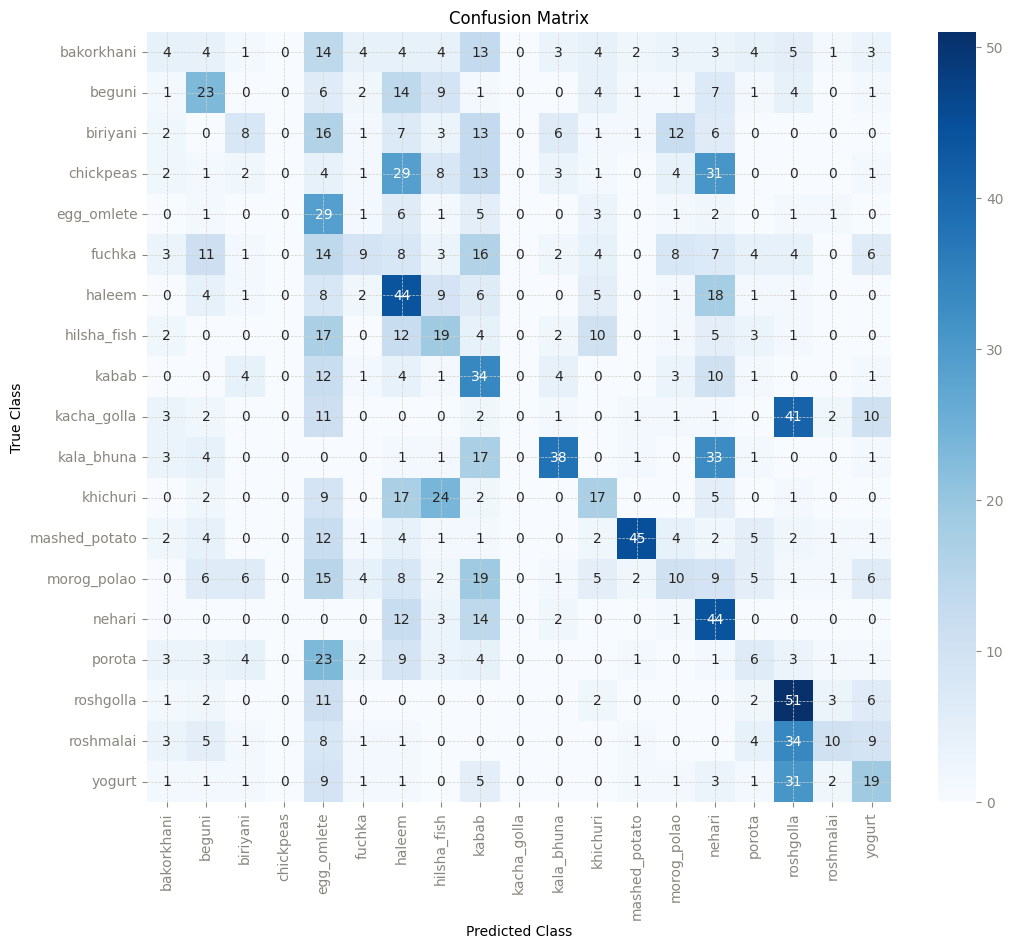

In [45]:

cm = confusion_matrix(all_labels, all_preds, labels=range(num_classes))
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")
plt.show()